# SIS 1 — Modelling Biological and Artificial Neurons

This notebook implements a Leaky Integrate-and-Fire (LIF) neuron and a
perceptron. The LIF simulation shows how input current changes membrane
voltage over time, including leakage, threshold crossings and resets.
The perceptron computes a weighted sum and produces a binary decision.

**How to run:** use a Python 3 notebook kernel with NumPy and Matplotlib,
then select **Restart Kernel and Run All Cells**. No datasets, downloads,
or external files are needed. Outputs are saved in this notebook.


In [1]:
%matplotlib inline
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# Use the same readable plot settings throughout the notebook.
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
print(f"Python {sys.version.split()[0]}")
print(f"NumPy {np.__version__}; Matplotlib {matplotlib.__version__}")


Python 3.12.14
NumPy 2.3.5; Matplotlib 3.11.2


## 1 Biological neuron model

The LIF model describes a passive membrane between spikes [1]:

$$\tau_m\frac{dV}{dt}=-(V-E_L)+R_m I(t).$$

Here $V$ is membrane voltage, $E_L$ is resting voltage, $\tau_m$ is the
membrane time constant, $R_m$ is resistance, and $I(t)$ is input current.
The leak term $-(V-E_L)$ pulls voltage toward rest; current drives it away.
At $V\geq V_{th}$, the model records a spike and resets to $V_{reset}$.

| Parameter | Value | Meaning |
|---|---:|---|
| $E_L$ | −65 mV | Resting potential |
| $V_{reset}$ | −65 mV | Potential immediately after a spike |
| $V_{th}$ | −50 mV | Firing threshold |
| $\tau_m$ | 20 ms | Membrane time constant |
| $R_m$ | 10 MΩ | Membrane resistance |
| $\Delta t$ | 0.1 ms | Simulation time step |

These are illustrative parameters. With current in nA and resistance in
MΩ, $R_m I$ is in mV. Forward Euler gives

$$V^*_{k+1}=V_k+\frac{\Delta t}{\tau_m}
\left[-(V_k-E_L)+R_m I_k\right].$$

If $V^*_{k+1}\geq V_{th}$, a spike is assigned to $t_{k+1}$ and the stored
voltage becomes $V_{reset}$. Otherwise it becomes $V^*_{k+1}$.
Spike times therefore have the resolution of the time grid.
The model represents spikes as events; it does not simulate their ionic
waveform. No refractory period is included.


In [2]:
def simulate_lif(input_current, dt_ms=0.1, tau_m_ms=20.0,
                 r_m_mohm=10.0, v_rest_mv=-65.0,
                 v_threshold_mv=-50.0, v_reset_mv=-65.0,
                 v0_mv=None):
    '''Return time (ms), voltage (mV), and a Boolean spike-event array.

    input_current[k] is the current in nA during [t[k], t[k+1]).
    The voltage stored at a spike time is the post-spike reset value.
    '''
    current = np.asarray(input_current, dtype=float)
    if current.ndim != 1 or not np.all(np.isfinite(current)):
        raise ValueError("input_current must be a finite one-dimensional array")
    if not 0 < dt_ms <= tau_m_ms:
        raise ValueError("Use a positive time step no larger than tau_m_ms")
    if v_reset_mv >= v_threshold_mv:
        raise ValueError("Reset voltage must be below threshold")

    n_steps = current.size
    time = np.arange(n_steps + 1) * dt_ms
    voltage = np.empty(n_steps + 1)
    spikes = np.zeros(n_steps + 1, dtype=bool)
    voltage[0] = v_rest_mv if v0_mv is None else v0_mv
    if voltage[0] >= v_threshold_mv:
        raise ValueError("Initial voltage must be below threshold")

    for k in range(n_steps):
        # Leakage opposes displacement from the resting potential.
        leak = -(voltage[k] - v_rest_mv)
        # Input current produces a voltage drive through resistance.
        drive = r_m_mohm * current[k]
        candidate = voltage[k] + (dt_ms / tau_m_ms) * (leak + drive)

        # Register threshold crossing, then immediately reset the state.
        if candidate >= v_threshold_mv:
            spikes[k + 1] = True
            voltage[k + 1] = v_reset_mv
        else:
            voltage[k + 1] = candidate

    return time, voltage, spikes


### Current input and spike generation

The 550 ms experiment contains a weak pulse of 1 nA from 50 to 150 ms,
followed by a strong pulse of 2 nA from 250 to 450 ms. Between pulses,
current is zero. This makes leakage visible after stimulation ends.

Under constant current, the subthreshold equilibrium is
$V_\infty=E_L+R_m I$. It is −55 mV for 1 nA and −45 mV for 2 nA.
The first value is below the firing threshold; the second is above it.


Simulation duration: 550.0 ms


Number of spikes: 7
Spike times (ms): [277.6 305.3 333.  360.7 388.4 416.1 443.8]


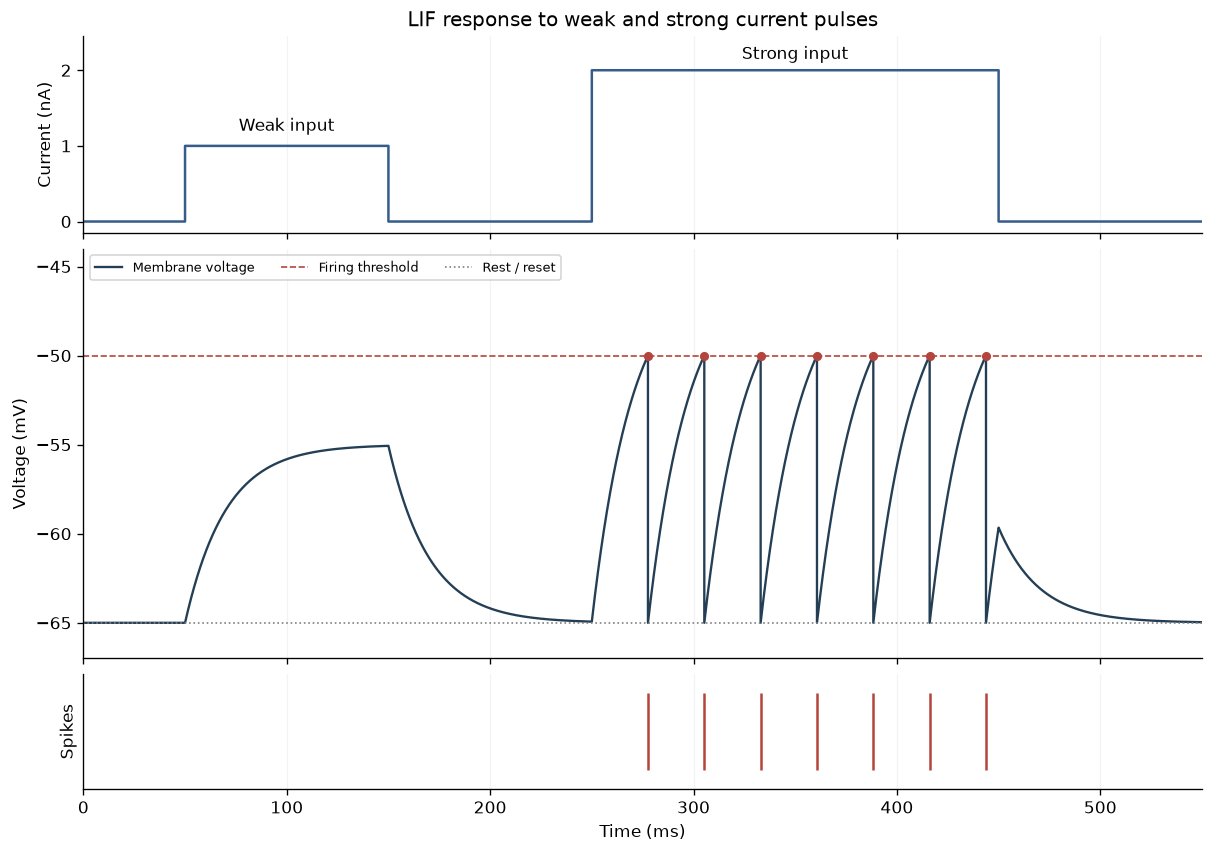

In [3]:
dt_ms = 0.1
duration_ms = 550.0
parameters = {
    "dt_ms": dt_ms,
    "tau_m_ms": 20.0,
    "r_m_mohm": 10.0,
    "v_rest_mv": -65.0,
    "v_threshold_mv": -50.0,
    "v_reset_mv": -65.0,
}

# Each current sample drives one integration interval.
input_times = np.arange(round(duration_ms / dt_ms)) * dt_ms
current_na = np.zeros(input_times.size)
current_na[(input_times >= 50) & (input_times < 150)] = 1.0
current_na[(input_times >= 250) & (input_times < 450)] = 2.0

time_ms, voltage_mv, spike_events = simulate_lif(current_na, **parameters)
spike_times_ms = time_ms[spike_events]
print(f"Simulation duration: {time_ms[-1]:.1f} ms")
print(f"Number of spikes: {spike_times_ms.size}")
print("Spike times (ms):", np.round(spike_times_ms, 1))

# Insert a threshold point before each reset for plotting only.
# The actual state remains voltage_mv; no action-potential shape is added.
plot_time, plot_voltage = [], []
for k, time_value in enumerate(time_ms):
    if spike_events[k]:
        plot_time.append(time_value)
        plot_voltage.append(parameters["v_threshold_mv"])
    plot_time.append(time_value)
    plot_voltage.append(voltage_mv[k])

fig, axes = plt.subplots(
    3, 1, figsize=(10, 7), sharex=True,
    gridspec_kw={"height_ratios": [1.2, 2.5, 0.7]},
    constrained_layout=True,
)
# Append one value so the step plot reaches the final time boundary.
axes[0].step(time_ms, np.r_[current_na, current_na[-1]],
             where="post", color="#355c8a")
axes[0].set(ylabel="Current (nA)", ylim=(-0.15, 2.45),
            title="LIF response to weak and strong current pulses")
axes[0].text(100, 1.2, "Weak input", ha="center")
axes[0].text(350, 2.15, "Strong input", ha="center")

axes[1].plot(plot_time, plot_voltage, color="#243f55", lw=1.4,
             label="Membrane voltage")
axes[1].axhline(parameters["v_threshold_mv"], color="#b4453c",
                ls="--", lw=1, label="Firing threshold")
axes[1].axhline(parameters["v_rest_mv"], color="gray", ls=":",
                lw=1, label="Rest / reset")
axes[1].scatter(spike_times_ms,
                np.full(spike_times_ms.size, parameters["v_threshold_mv"]),
                color="#b4453c", s=20, zorder=3)
axes[1].set(ylabel="Voltage (mV)", ylim=(-67, -44))
axes[1].legend(loc="upper left", ncols=3, fontsize=8)

axes[2].eventplot(spike_times_ms, colors="#b4453c", linelengths=0.8)
axes[2].set(xlabel="Time (ms)", ylabel="Spikes", yticks=[],
            ylim=(0.4, 1.6), xlim=(0, duration_ms))
for ax in axes:
    ax.grid(axis="x", alpha=0.15)
plt.show()


The weak pulse depolarizes the membrane without producing a spike.
When it ends, voltage relaxes toward −65 mV. The strong pulse causes
repeated threshold crossings, each followed by a reset.
Red markers show threshold events, and the bottom panel shows their times.


### Numerical checks

For a constant current without threshold crossings, the exact solution is

$$V(t)=V_\infty+(V(0)-V_\infty)e^{-t/\tau_m}.$$

The following checks compare Euler integration with this solution,
verify leakage and the reset state, and compare the simulated interval
between spikes with

$$T=\tau_m\ln\!\left(\frac{V_\infty-V_{reset}}
{V_\infty-V_{th}}\right), \qquad V_\infty>V_{th}.$$


In [4]:
# Check that zero current preserves a neuron initially at rest.
_, rest_voltage, rest_spikes = simulate_lif(np.zeros(1000), **parameters)
assert np.allclose(rest_voltage, parameters["v_rest_mv"])
assert not rest_spikes.any()

# Check that a displaced voltage leaks back toward rest without input.
decay_t, decay_v, decay_spikes = simulate_lif(
    np.zeros(1000), v0_mv=-55.0, **parameters
)
exact_decay = -65.0 + 10.0 * np.exp(-decay_t / parameters["tau_m_ms"])
decay_error = np.max(np.abs(decay_v - exact_decay))
assert not decay_spikes.any()
assert np.all(np.diff(decay_v) < 0)
assert decay_error < 0.02  # mV tolerance for dt = 0.1 ms

# Check the subthreshold response against the analytical solution.
weak_t, weak_v, weak_spikes = simulate_lif(np.ones(2000), **parameters)
exact_weak = -55.0 - 10.0 * np.exp(-weak_t / parameters["tau_m_ms"])
weak_error = np.max(np.abs(weak_v - exact_weak))
assert not weak_spikes.any()
assert weak_error < 0.02

# Check spike generation, instantaneous reset, and interspike interval.
strong_t, strong_v, strong_spikes = simulate_lif(
    np.full(2000, 2.0), **parameters
)
assert strong_spikes.sum() >= 2
assert np.all(strong_v[strong_spikes] == parameters["v_reset_mv"])
v_infinity = parameters["v_rest_mv"] + parameters["r_m_mohm"] * 2.0
exact_interval = parameters["tau_m_ms"] * np.log(
    (v_infinity - parameters["v_reset_mv"])
    / (v_infinity - parameters["v_threshold_mv"])
)
simulated_interval = np.diff(strong_t[strong_spikes]).mean()
assert abs(simulated_interval - exact_interval) < dt_ms

# Check that the main experiment only fires during the strong pulse.
assert spike_times_ms.size > 0
assert np.all((spike_times_ms > 250) & (spike_times_ms <= 450))

print("All LIF checks passed.")
print(f"Maximum passive-decay error: {decay_error:.5f} mV")
print(f"Maximum subthreshold error: {weak_error:.5f} mV")
print(f"Analytical interspike interval: {exact_interval:.4f} ms")
print(f"Simulated interspike interval:  {simulated_interval:.4f} ms")


All LIF checks passed.
Maximum passive-decay error: 0.00922 mV
Maximum subthreshold error: 0.00922 mV
Analytical interspike interval: 27.7259 ms
Simulated interspike interval:  27.7000 ms


## 2 Artificial neuron model

A perceptron combines inputs using weights and a bias, then applies a
step activation [2]:

$$s=\sum_{i=1}^{n}w_i x_i, \qquad z=s+b, \qquad
y=\begin{cases}1,&z\geq0,\\0,&z<0.\end{cases}$$

The bias is equivalent to a threshold $\theta=-b$ on $s$.
The convention at the boundary is explicit: $z=0$ produces 1.
For the AND example, choose $w_1=w_2=1$ and $b=-1.5$.
Weights are specified directly; no training is needed for this example.


In [5]:
def perceptron(inputs, weights, bias=0.0):
    '''Return weighted sum, score including bias, and binary output.

    A row of inputs represents one example. A single input vector is
    also accepted. The last input dimension must match the weights.
    '''
    inputs = np.asarray(inputs, dtype=float)
    weights = np.asarray(weights, dtype=float)

    # Multiplication by weights sets each input's contribution.
    weighted_sum = inputs @ weights
    # Bias shifts the location of the decision threshold.
    score = weighted_sum + bias
    # Step activation converts the score into a binary prediction.
    output = (score >= 0.0).astype(int)
    return weighted_sum, score, output


inputs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
weights = np.array([1.0, 1.0])
bias = -1.5
expected_and = np.array([0, 0, 0, 1])

weighted_sums, scores, predictions = perceptron(inputs, weights, bias)
print("x1  x2  weighted sum  score z  output  expected AND")
for x, total, score, prediction, expected in zip(
    inputs, weighted_sums, scores, predictions, expected_and
):
    print(f"{x[0]:2d}  {x[1]:2d}  {total:12.1f}  {score:7.1f}"
          f"  {prediction:6d}  {expected:12d}")

np.testing.assert_array_equal(predictions, expected_and)
assert set(predictions).issubset({0, 1})
# Verify the chosen step convention exactly at the threshold.
_, boundary_score, boundary_output = perceptron([1, 0.5], weights, bias)
assert boundary_score == 0.0 and boundary_output == 1
print("\nAll perceptron checks passed, including the threshold boundary.")


x1  x2  weighted sum  score z  output  expected AND
 0   0           0.0     -1.5       0             0
 0   1           1.0     -0.5       0             0
 1   0           1.0     -0.5       0             0
 1   1           2.0      0.5       1             1

All perceptron checks passed, including the threshold boundary.


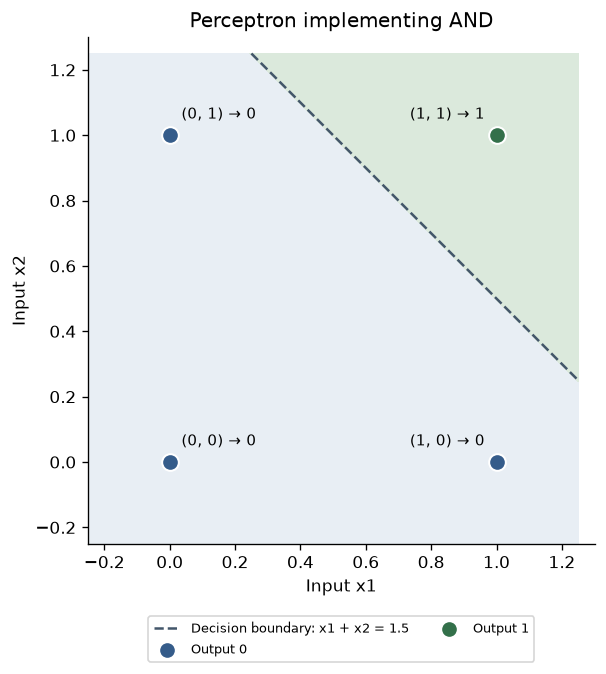

In [6]:
# Evaluate the same perceptron on a grid to show its decision regions.
grid_x1, grid_x2 = np.meshgrid(
    np.linspace(-0.25, 1.25, 151),
    np.linspace(-0.25, 1.25, 151),
)
grid_inputs = np.stack([grid_x1, grid_x2], axis=-1)
_, _, grid_predictions = perceptron(grid_inputs, weights, bias)

fig, ax = plt.subplots(figsize=(6.8, 5.5), constrained_layout=True)
ax.contourf(grid_x1, grid_x2, grid_predictions,
            levels=[-0.5, 0.5, 1.5], colors=["#e8eef4", "#dbe9dc"])
boundary_x1 = np.linspace(0.25, 1.25, 100)
ax.plot(boundary_x1, 1.5 - boundary_x1, color="#43566a", ls="--",
        label="Decision boundary: x1 + x2 = 1.5")
for output, color in [(0, "#355c8a"), (1, "#33704a")]:
    selected = predictions == output
    ax.scatter(inputs[selected, 0], inputs[selected, 1], color=color,
               s=100, edgecolors="white", linewidths=1.2,
               label=f"Output {output}", zorder=3)
for x, prediction in zip(inputs, predictions):
    offset = 7 if x[0] == 0 else -7
    ax.annotate(f"({x[0]}, {x[1]}) → {prediction}", x,
                xytext=(offset, 10), textcoords="offset points", fontsize=9,
                ha="left" if x[0] == 0 else "right")
ax.set(xlabel="Input x1", ylabel="Input x2",
       title="Perceptron implementing AND",
       xlim=(-0.25, 1.3), ylim=(-0.25, 1.3), aspect="equal")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13),
          ncols=2, fontsize=8)
plt.show()


The perceptron returns 1 only for $(1,1)$, matching AND for all four
binary input combinations. The dashed line is where the score equals
zero. Inputs on or above that line receive output 1.

## 3 Brief comparison

| Feature | Biological neuron represented by LIF | Artificial perceptron |
|---|---|---|
| Input | Current varying with time | Numeric feature vector |
| Integration | Voltage accumulates input over time | Weighted sum of the current inputs |
| Memory | Previous voltage affects the next state | No temporal state in this implementation |
| Leakage | Voltage relaxes toward rest | No membrane leakage |
| Threshold response | Spike event followed by voltage reset | Binary output from a step function |
| Output | Spike times and membrane voltage | A class value of 0 or 1 |

Both models combine inputs and apply a threshold. LIF preserves a
changing internal state, so the timing and history of stimulation matter.
The perceptron makes a decision from one input vector. Its boundary is
linear, and a single perceptron cannot represent XOR [2]. LIF is a
simplified model of a biological neuron rather than a complete account
of its physiology. Neither implementation here learns its parameters.

## References

1. Gerstner, W., Kistler, W. M., Naud, R., and Paninski, L. (2014).
   *Neuronal Dynamics*, Section 1.3, Integrate-and-Fire Models.
   [Online textbook](https://neuronaldynamics.epfl.ch/online/Ch1.S3.html).
2. Cornell University, CS4780 (2018). *Lecture 3 — The Perceptron*.
   [Course notes](https://www.cs.cornell.edu/courses/cs4780/2018fa/lectures/lecturenote03.html).
